## Support Vector Machine (SVM)

### Theorie

Een **Support Vector Machine (SVM)** is een classificatiealgoritme dat een grens zoekt tussen twee klassen. In dit onderzoek zijn dat patiënten **met** en **zonder** stroke. Het doel is een beslissingsgrens te vinden die beide groepen zo goed mogelijk van elkaar scheidt.

Bij een lineaire SVM is deze grens een recht vlak. De observaties die het dichtst bij die grens liggen, heten **support vectors**. Zij zijn het belangrijkst voor de positie van de beslissingsgrens. Een SVM probeert de marge, de ruimte tussen de grens en de dichtstbijzijnde observaties van beide klassen, zo groot mogelijk te maken.


### Soft margin en parameter `C`


In echte data zijn de groepen meestal niet perfect van elkaar te scheiden. Daarom staat een SVM fouten toe: sommige observaties mogen aan de verkeerde kant van de grens liggen. Dit heet een **soft margin**.

De parameter `C` bepaalt de afweging tussen een brede, eenvoudige grens en het correct classificeren van trainingsobservaties:

- Een **lage `C`** staat meer fouten toe en geeft een eenvoudiger model. Dit kan leiden tot underfitting.
- Een **hoge `C`** straft fouten sterker af. Het model past zich dan nauwkeuriger aan de trainingsdata aan, met een groter risico op overfitting.


### Lineaire en niet-lineaire SVM

`LinearSVC` gebruikt een lineaire beslissingsgrens. Dit model is relatief snel en geschikt voor grotere datasets, zoals deze dataset met 33.550 patiënten.

Wanneer een lineaire grens onvoldoende is, kan `SVC` met een **RBF-kernel** worden gebruikt. De RBF-kernel kan niet-lineaire patronen herkennen. Hierbij bepaalt `gamma` hoe lokaal de invloed van een observatie is:

- Een **lage `gamma`** geeft een gladdere, minder complexe beslissingsgrens.
- Een **hoge `gamma`** geeft een complexere grens die sterker op individuele observaties reageert en daardoor kan overfitten.

De parameters `C` en `gamma` worden met cross-validatie afgestemd.

### Waarom schalen nodig is



SVM's zijn gevoelig voor de schaal van variabelen. In deze dataset hebben kenmerken zoals `avg_glucose_level` en `age` een veel groter bereik dan dummyvariabelen met alleen de waarden 0 en 1. Zonder schaling kunnen kenmerken met grote waarden te veel invloed krijgen op het model.

Daarom wordt `StandardScaler` gebruikt. Deze preprocessing wordt in een `Pipeline` geplaatst, zodat de scaler alleen op de trainingsdata wordt geleerd. Hiermee wordt datalekken voorkomen.

### Class imbalance en evaluatie

Slechts 1,54% van de patiënten in de dataset heeft een stroke. Daarom wordt `class_weight='balanced'` gebruikt, zodat fouten bij de zeldzame klasse zwaarder meetellen. Ook wordt gestratificeerde cross-validatie toegepast, zodat de verhouding tussen strokes en geen strokes in elke fold behouden blijft.

De prestaties worden primair beoordeeld met de **F1-score**. Deze maat combineert precision en recall en is geschikter dan accuracy bij een sterk ongebalanceerde targetvariabele.

### Praktische keuze



Een SVM met RBF-kernel kan bij grote datasets rekenintensief zijn. Daarom vormt `LinearSVC` een praktisch uitgangspunt. Een RBF-SVM wordt alleen als aanvullende variant getest met een beperkte hyperparameterzoektocht. Voor beide varianten kan de beslissingsdrempel worden geoptimaliseerd op basis van de F1-score, omdat de standaarddrempel niet noodzakelijk de beste resultaten geeft voor de zeldzame stroke-klasse.


In [108]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, RepeatedStratifiedKFold, RandomizedSearchCV, GridSearchCV, TunedThresholdClassifierCV,cross_val_predict

from sklearn.metrics import ConfusionMatrixDisplay, classification_report, precision_recall_curve

from sklearn.model_selection import cross_val_score
from sklearn.metrics import f1_score
from sklearn.linear_model import LogisticRegression


In [109]:
pd.set_option("display.max_columns", 30)
data = pd.read_csv('train.csv')

In [110]:
dropcols = ['id', 'gender_Male', 'ever_married_No', 'work_type_Govt_job', 'Residence_type_Rural']

In [111]:
df = data.drop(dropcols, axis=1)

In [112]:
def bool_to_num(dataframe):

    """ 
    Maak boolean kolommen nummeriek.
    Geef data set terug met omgezette kolommen.
    """

    for i in dataframe.select_dtypes(include='bool').columns:
        dataframe[i] = dataframe[i].astype(int)

    return dataframe

    


def standardiseer(X_train, X_test):

    """
    Standaardiseer X_train en X_test individueel
    Geef twee datasets terug met gestandaardiseerde waarden.
    """

    scaler = StandardScaler()
    train = scaler.fit_transform(X_train) #Gemiddelde en standaarddeviatie wordt berekend op traindata
    test = scaler.transform(X_test)       #Gemiddelde en standaarddeviatie wordt overgenomen van traindata --> geen data-lekkage

    return train, test


In [113]:
df_stroke = bool_to_num(df) 

X = df_stroke.drop('stroke', axis=1) 
y = df_stroke['stroke']


X_train, X_val, y_train, y_val = train_test_split(X, y, stratify=y, random_state=42)
X_train, X_val = standardiseer(X_train, X_val)

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42) #gebruik deze cross validation bij hyperparameter tunen

In [114]:
test_df = pd.read_csv('test.csv')
test_ids = test_df['id']          # id's bewaren voordat je kolommen dropt

X_test_final = bool_to_num(test_df).drop(dropcols, axis=1)

#Fit je model hierop voor het submitten
X_train_final = df_stroke.drop('stroke', axis=1) 
y_train_final = df_stroke['stroke']

X_train_final, X_test_final = standardiseer(X_train_final, X_test_final)

### Support Vector Machine (SVM)

#### SVM base model

In [115]:
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
svm_basis = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="rbf"))
])

svm_basis.fit(X_train, y_train)
y_pred = svm_basis.predict(X_val)

#ConfusionMatrixDisplay.from_predictions(y_val, y_pred)
#print(classification_report(y_val, y_pred, digits=3, zero_division=0))

svc_basis = svm_basis.named_steps["svm"]
#print(f"Aantal support vectors: {svc_basis.support_vectors_.shape[0]}")
#print(f"Per klasse (geen stroke / stroke): {svc_basis.n_support_}")

#### SVM class weight balanced 

In [116]:
svm_bal = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="rbf", class_weight="balanced"))
])

svm_bal.fit(X_train, y_train)
y_pred = svm_bal.predict(X_val)

#ConfusionMatrixDisplay.from_predictions(y_val, y_pred)
#print(classification_report(y_val, y_pred, digits=3, zero_division=0))

#### SVM hyperparameter

In [117]:
indices = np.arange(len(X_train))

_, sub_idx = train_test_split(
    indices,
    test_size=6000,
    stratify=y_train,
    random_state=42
)

if hasattr(X_train, "iloc"):
    X_sub = X_train.iloc[sub_idx]
else:
    X_sub = X_train[sub_idx]

y_sub = np.asarray(y_train)[sub_idx]

print(f"Subsample: {X_sub.shape[0]} rijen, "f"waarvan {y_sub.sum()} met stroke "f"({y_sub.mean():.2%})")

Subsample: 6000 rijen, waarvan 93 met stroke (1.55%)


#### Hyperparameters tunen

In [118]:
param_grid = {
    "svm__C": [0.1, 1, 10, 100],
    "svm__gamma": [0.001, 0.01, 0.1, "scale"],
}

cv_svm = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(
        kernel="rbf",
        class_weight="balanced",
        cache_size=1000
    ))
])

grid = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=cv_svm,
    n_jobs=-1,
    verbose=1,
    return_train_score=False
)

grid.fit(X_sub, y_sub)

print(f"Beste parameters: {grid.best_params_}")
print(f"Beste F1-score in cross-validatie: {grid.best_score_:.4f}")

Fitting 3 folds for each of 16 candidates, totalling 48 fits
Beste parameters: {'svm__C': 0.1, 'svm__gamma': 'scale'}
Beste F1-score in cross-validatie: 0.0880


#### Overzicht van alle hyperparameter resultaten 

In [119]:
resultaten = pd.DataFrame(grid.cv_results_)[
    [
        "param_svm__C",
        "param_svm__gamma",
        "mean_test_score",
        "std_test_score",
        "rank_test_score",
    ]
]

resultaten = resultaten.sort_values(
    "mean_test_score",
    ascending=False
)

print(resultaten.to_string(index=False))

 param_svm__C param_svm__gamma  mean_test_score  std_test_score  rank_test_score
          0.1            scale         0.087951        0.004561                1
        100.0            0.001         0.084796        0.003383                2
          0.1             0.01         0.084392        0.005182                3
          1.0            0.001         0.083942        0.006253                4
         10.0            0.001         0.083752        0.005822                5
          0.1            0.001         0.082791        0.004435                6
          1.0             0.01         0.081985        0.009241                7
          0.1              0.1         0.077184        0.005341                8
         10.0             0.01         0.074331        0.002810                9
        100.0             0.01         0.066730        0.008783               10
         10.0            scale         0.057202        0.005847               11
          1.0            sca

#### Hertrainen op de volledige trainingsset en eerste validatie


In [120]:
svm_best = grid.best_estimator_

svm_best.fit(X_train, y_train)

y_pred = svm_best.predict(X_val)

#ConfusionMatrixDisplay.from_predictions(y_val, y_pred)
#print(classification_report(y_val, y_pred, digits=3, zero_division=0))

svc_best = svm_best.named_steps["svm"]
aantal_sv = svc_best.support_vectors_.shape[0]

print(
    f"Support vectors: {aantal_sv} "
    f"({aantal_sv / len(X_train):.1%} van de trainingsset)"
)

Support vectors: 12269 (48.8% van de trainingsset)


#### Cross validation met de beste SVM model

In [121]:
cv_scores = cross_val_score(
    svm_best,
    X_train,
    y_train,
    cv=cv_svm,
    scoring="f1",
    n_jobs=-1
)

print(f"F1-score per fold: {np.round(cv_scores, 4)}")
print(
    f"Gemiddelde F1-score: {cv_scores.mean():.4f} "
    f"(+/- {cv_scores.std():.4f})"
)

Exception ignored in: <function ResourceTracker.__del__ at 0x105eb9bc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes


F1-score per fold: [0.0846 0.093  0.0917]
Gemiddelde F1-score: 0.0898 (+/- 0.0037)


Exception ignored in: <function ResourceTracker.__del__ at 0x1061e1bc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes


#### SVM eindmodel 

In [122]:
def threshold_finder_svm(model, X_data, y_data):
    """
    Zoekt de threshold op de decision function die de F1-score maximaliseert.
    """
    scores = model.decision_function(X_data)

    precision, recall, thresholds = precision_recall_curve(y_data, scores)

    f1_scores = (
        2 * precision[:-1] * recall[:-1]
        / (precision[:-1] + recall[:-1] + 1e-12)
    )

    return thresholds[np.argmax(f1_scores)]

In [123]:
train_scores_oof = cross_val_predict(
    svm_best,
    X_train,
    y_train,
    cv=cv_svm,
    method="decision_function",
    n_jobs=-1
)

precision, recall, thresholds = precision_recall_curve(
    y_train,
    train_scores_oof
)

f1_scores = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-12)
)

best_threshold = thresholds[np.argmax(f1_scores)]

print(f"Beste threshold op out-of-fold trainingsscores: {best_threshold:.4f}")
print(f"Beste out-of-fold F1-score: {np.max(f1_scores):.4f}")

Exception ignored in: <function ResourceTracker.__del__ at 0x102fd1bc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x106835bc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes


Beste threshold op out-of-fold trainingsscores: 0.8471
Beste out-of-fold F1-score: 0.1158


Exception ignored in: <function ResourceTracker.__del__ at 0x10734dbc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes


Exception ignored in: <function ResourceTracker.__del__ at 0x1026a1bc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes


              precision    recall  f1-score   support

           0      0.990     0.912     0.950      8259
           1      0.068     0.411     0.117       129

    accuracy                          0.905      8388
   macro avg      0.529     0.662     0.533      8388
weighted avg      0.976     0.905     0.937      8388

F1-score op de onafhankelijke validatieset (met vaste threshold): 0.1170


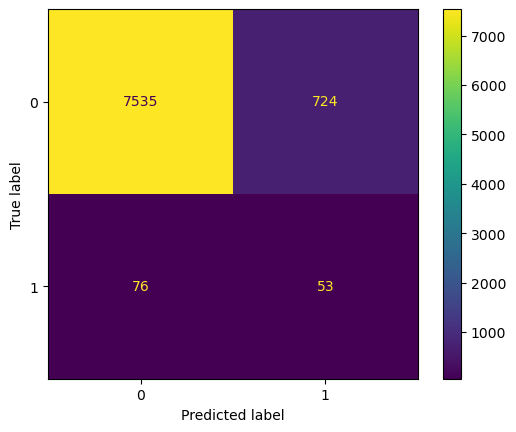

In [124]:
# svm_best is al gefit op de volledige trainingsset.
val_scores = svm_best.decision_function(X_val)

y_pred_threshold = (
    val_scores >= best_threshold
).astype(int)

ConfusionMatrixDisplay.from_predictions(y_val, y_pred_threshold)

print(
    classification_report(
        y_val,
        y_pred_threshold,
        digits=3,
        zero_division=0
    )
)

print(
    "F1-score op de onafhankelijke validatieset "
    f"(met vaste threshold): {f1_score(y_val, y_pred_threshold):.4f}"
)

## Logistic Regression


### Theorie

#### Hoe werkt het model?

**Logistic Regression** is, ondanks de naam, een **classificatie-algoritme**. Het model is bedoeld om bij een rij features $x = (x_1, x_2, \dots, x_n)$ een **kans** te voorspellen dat die rij tot de positieve klasse behoort (in ons geval: *stroke = 1*). Het model doet dit in twee stappen: eerst een lineaire combinatie van de features, daarna een transformatie met de sigmoid-functie zodat de uitkomst tussen 0 en 1 ligt.

**Stap 1 — lineaire combinatie van de features**

Net als bij lineaire regressie berekent het model eerst een gewogen som van de features plus een bias-term:

$$
z = w_0 + w_1 x_1 + w_2 x_2 + \dots + w_n x_n = \mathbf{w}^\top \mathbf{x} + b
$$

In deze formule stelt $x_i$ de waarde van feature $i$ voor (bijvoorbeeld `age`, `avg_glucose_level` of `hypertension`). Het bijbehorende gewicht $w_i$ is de coëfficiënt die het model voor die feature heeft geleerd: een groot positief gewicht betekent dat de feature de kans op stroke verhoogt, terwijl een negatief gewicht die kans juist verlaagt. De term $b$ is de bias (intercept) en het eindresultaat $z$ noemen we de *logit*, een getal dat tussen $-\infty$ en $+\infty$ ligt.

**Stap 2 — sigmoid-functie om de logit om te zetten in een kans**

De logit $z$ wordt door de **sigmoid-functie** $\sigma(\cdot)$ geperst, zodat de uitkomst altijd tussen $0$ en $1$ ligt:

$$
\hat{y} = P(y=1 \mid \mathbf{x}) = \sigma(z) = \frac{1}{1 + e^{-z}}
$$

De uitkomst $\hat{y}$ is de voorspelde kans dat de patiënt een stroke heeft. Standaard wordt met een drempelwaarde (threshold) van $0{,}5$ beslist tot welke klasse de voorspelling behoort: bij $\hat{y} \geq 0{,}5$ voorspelt het model klasse $1$, anders klasse $0$. Omdat onze dataset sterk imbalanced is, gebruiken we net als bij de andere modellen `threshold_finder()` om een betere drempelwaarde voor de F1-score te zoeken.

**Waarom schalen we bij Logistic Regression?**

Logistic Regression leert de gewichten $w_i$ door een loss-functie te minimaliseren met gradient descent. Features met grote waarden (zoals `avg_glucose_level` met waarden tot ongeveer $280$) krijgen daardoor automatisch kleinere gewichten, terwijl features met kleine waarden (zoals `hypertension` met $0$ of $1$) juist grotere gewichten krijgen. Bovendien beïnvloedt de L1/L2-regularisatie (zie verder) alle gewichten op dezelfde schaal. Als de features op heel verschillende schalen staan, is dat oneerlijk: features met grote getallen worden harder "gestraft". We standaardiseren daarom met `StandardScaler`, net als bij KNN.

### Loss-functie: Binary Cross-Entropy (Log Loss)

Om de gewichten $\mathbf{w}$ en de bias $b$ te leren, moet het model weten hoe fout zijn voorspellingen zijn. Dit meten we met de **binary cross-entropy** (ook wel *log loss* genoemd):

$$
\mathcal{L}(\mathbf{w}, b) = -\frac{1}{m} \sum_{i=1}^{m} \Big[\, y_i \log(\hat{y}_i) + (1 - y_i)\log(1 - \hat{y}_i) \,\Big]
$$

Hierin is $m$ het aantal trainingsvoorbeelden, is $y_i \in \{0, 1\}$ de werkelijke klasse van patiënt $i$, en is $\hat{y}_i = \sigma(\mathbf{w}^\top \mathbf{x}_i + b)$ de voorspelde kans voor diezelfde patiënt.

**Intuïtie.** Voor een echte stroke-patiënt ($y_i = 1$) telt alleen de term $\log(\hat{y}_i)$ mee. Voorspelt het model een kans van bijna $1$, dan is $\log(\hat{y}_i)$ bijna $0$ en is de loss laag. Voorspelt het model juist een kans van bijna $0$, dan gaat $\log(\hat{y}_i)$ naar $-\infty$ en wordt de loss enorm groot. Voor een gezonde patiënt ($y_i = 0$) telt alleen $\log(1 - \hat{y}_i)$ mee en geldt precies hetzelfde idee, maar omgekeerd. De loss straft dus vooral **zelfverzekerde foute voorspellingen** zwaar af — precies wat je wilt bij een medisch probleem.

### Gradient Descent

#### Wat is gradient descent in deze context?


Er bestaat geen formule waarmee we $\mathbf{w}$ en $bdirect kunnen uitrekenen zoals bij lineaire regressie met de kleinste-kwadratenmethode. In plaats daarvan gebruikt scikit-learn een **iteratief optimalisatie-algoritme** om de loss te minimaliseren. Gradient descent is daarvan de bekendste vorm.

Het idee is simpel: begin met willekeurige (of nul-)gewichten en zet elke iteratie een kleine stap in de richting waarin de loss het snelst daalt. Die richting is de **negatieve gradient** van de loss. De update-regel voor elk gewicht $w_j$ en voor de bias $b$ luidt:

$$
w_j := w_j - \eta \cdot \frac{\partial \mathcal{L}}{\partial w_j}
\qquad\text{en}\qquad
b := b - \eta \cdot \frac{\partial \mathcal{L}}{\partial b}
$$

De factor $\eta$ heet de *learning rate* en bepaalt de stapgrootte. Voor logistic regression blijken de partiële afgeleiden mooi eenvoudig te zijn:

$$
\frac{\partial \mathcal{L}}{\partial w_j} = \frac{1}{m} \sum_{i=1}^{m} (\hat{y}_i - y_i)\, x_{ij}
\qquad\text{en}\qquad
\frac{\partial \mathcal{L}}{\partial b} = \frac{1}{m} \sum_{i=1}^{m} (\hat{y}_i - y_i)
$$

In woorden: de fout $(\hat{y}_i - y_i)$ wordt vermenigvuldigd met de bijbehorende feature-waarde en gemiddeld over alle trainingsvoorbeelden.

#### Eenvoudig rekenvoorbeeld

Stel we hebben één feature (bijvoorbeeld de gestandaardiseerde leeftijd) en drie trainingsvoorbeelden:

| $i$ | $x_i$ | $y_i$ |
|---|---:|---:|
| 1 | $-1$ | $0$ |
| 2 | $\;\,0$ | $0$ |
| 3 | $\;\,1$ | $1$ |

We beginnen met $w = 0$ en $b = 0$, en kiezen een learning rate van $\eta = 1$.

**Forward pass.** Omdat $w = 0$ en $b = 0$ geldt voor elk voorbeeld $z_i = 0$ en dus $\hat{y}_i = \sigma(0) = 0{,}5$. De fouten $(\hat{y}_i - y_i)$ worden daarmee respectievelijk $0{,}5$, $0{,}5$ en $-0{,}5$.

**Gradient van $w$.** Invullen van de formule geeft:

$$
\frac{\partial \mathcal{L}}{\partial w} = \frac{1}{3}\big(0{,}5 \cdot (-1) + 0{,}5 \cdot 0 + (-0{,}5) \cdot 1\big) = \frac{-1}{3} \approx -0{,}333
$$

**Gradient van $b$.** Op dezelfde manier:

$$
\frac{\partial \mathcal{L}}{\partial b} = \frac{1}{3}\big(0{,}5 + 0{,}5 - 0{,}5\big) = \frac{0{,}5}{3} \approx 0{,}167
$$

**Update van de parameters.** Met $\eta = 1$ wordt het nieuwe gewicht $w := 0 - 1 \cdot (-0{,}333) = 0{,}333$ en de nieuwe bias $b := 0 - 1 \cdot 0{,}167 = -0{,}167$.

**Controle.** Voor voorbeeld 3 (de echte stroke-patiënt) krijgen we nu $z_3 = 0{,}333 \cdot 1 + (-0{,}167) = 0{,}166$ en dus $\hat{y}_3 = \sigma(0{,}166) \approx 0{,}541$. De voorspelde kans voor deze patiënt is dus gestegen van $0{,}5$ naar ongeveer $0{,}541$, precies wat we willen. Als we dit duizenden iteraties herhalen, convergeren de gewichten naar de combinatie die de totale log loss minimaliseert. Scikit-learn gebruikt onder de motorkap efficiëntere varianten (`lbfgs`, `liblinear`, `saga`), maar het onderliggende principe is hetzelfde.

### Regularisatie

Logistic Regression kan overfitten door **sommige gewichten extreem groot te laten worden**, vooral als er veel (gecorreleerde) features zijn. Regularisatie voegt een **strafterm** aan de loss toe die grote gewichten ontmoedigt. Scikit-learn ondersteunt vier varianten via de parameter `penalty`: L2, L1, Elastic Net en geen regularisatie.

#### 1. L2-regularisatie (`penalty='l2'`) — standaard

De L2-variant voegt het **kwadraat** van elk gewicht toe aan de loss:

$$
\mathcal{L}_{\text{L2}}(\mathbf{w}, b) = \mathcal{L}(\mathbf{w}, b) + \frac{1}{2C} \sum_{j=1}^{n} w_j^2
$$

Het effect is dat alle gewichten richting $0$ worden geduwd, maar vrijwel nooit precies $0$ worden. Het model blijft dus alle features gebruiken, maar met kleinere, stabielere coëfficiënten. L2 is bovendien sterk tegen multicollineariteit, wat handig is omdat onze dataset veel dummy-kolommen bevat. De hyperparameter $C$ in scikit-learn is de **inverse** van de regularisatiesterkte: een kleine $C$ geeft dus een sterke regularisatie, een grote $C$ een zwakke.

#### 2. L1-regularisatie (`penalty='l1'`)

De L1-variant straft de **absolute waarde** van elk gewicht:

$$
\mathcal{L}_{\text{L1}}(\mathbf{w}, b) = \mathcal{L}(\mathbf{w}, b) + \frac{1}{C} \sum_{j=1}^{n} |w_j|
$$

Het effect is dat sommige gewichten exact naar $0$ worden geduwd. L1 doet daarmee **automatisch feature-selectie**: minder relevante features vallen volledig weg. Dit is handig als je vermoedt dat sommige van de 20 features (bijvoorbeeld zeldzame dummy's zoals `work_type_Never_worked`) weinig toevoegen aan de voorspelling.

#### 3. Elastic Net (`penalty='elasticnet'`)

Elastic Net combineert L1 en L2 in één strafterm, gestuurd door de mengparameter $\rho$ (in scikit-learn: `l1_ratio`):

$$
\mathcal{L}_{\text{EN}}(\mathbf{w}, b) = \mathcal{L}(\mathbf{w}, b) + \frac{1}{C}\left(\rho \sum_j |w_j| + \frac{1 - \rho}{2}\sum_j w_j^2\right)
$$

Bij $\rho = 0$ krijg je puur L2, bij $\rho = 1$ puur L1, en daartussen een mengvorm. Het effect is dat je zowel de **feature-selectie van L1** als de **stabiliteit van L2** krijgt. In scikit-learn werkt Elastic Net alleen in combinatie met de solver `saga`.

#### 4. Geen regularisatie (`penalty=None`)


Zonder strafterm wordt gewoon de pure log loss geminimaliseerd:

$$
\mathcal{L}_{\text{None}}(\mathbf{w}, b) = \mathcal{L}(\mathbf{w}, b)
$$

Deze variant geeft een grote kans op overfitting als het aantal features groot is of als features onderling gecorreleerd zijn. In de praktijk dient `penalty=None` vooral als vergelijkingsbaseline om te zien hoeveel de regularisatie werkelijk toevoegt.

### Hoe verhoudt regularisatie zich tot overfitting?


**Overfitting** betekent dat het model de **ruis** in de trainingsdata uit zijn hoofd leert: het presteert bijna perfect op de training set maar slecht op nieuwe (validatie-)data. Bij Logistic Regression ontstaat dit vooral doordat sommige gewichten extreem groot worden om zelfs individuele trainingsvoorbeelden perfect te kunnen voorspellen.

Regularisatie werkt als een tegenkracht: de strafterm maakt grote gewichten letterlijk duur in de loss. Het model wordt daardoor gedwongen om alleen gewichten groot te maken als dat écht een duidelijke verlaging van de log loss oplevert. Een te sterke regularisatie (kleine $C$) houdt alle gewichten dicht bij $0$, waardoor het model te simpel wordt en gaat **underfitten**. Een te zwakke regularisatie (grote $C$ of `penalty=None`) geeft de gewichten vrij spel en leidt juist tot **overfitting**. Pas met een goed afgestemde regularisatie leert het model alleen de echte, generaliseerbare patronen en behaalt het de beste F1-score op validatie- en testset. De juiste hoeveelheid regularisatie — dus de combinatie van $C$, `penalty` en bij Elastic Net ook $\rho$ — vinden we net als bij de andere modellen via **cross-validation**.

### Hyperparameter tuning

De officiële [scikit-learn documentatie van `LogisticRegression`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html) beschrijft welke solvers welke `penalty`-waarden ondersteunen. Hierop baseren we het grid:

| Solver | Ondersteunde penalties |
|---|---|
| `lbfgs` *(default)* | `l2`, `None` |
| `liblinear` | `l1`, `l2` |
| `saga` | `l1`, `l2`, `elasticnet`, `None` |
| `newton-cg`, `newton-cholesky`, `sag` | `l2`, `None` |

We tunen daarom via **GridSearchCV** met dezelfde `cv` (`RepeatedStratifiedKFold`) en scoring (`f1`) als bij de andere modellen:

| Hyperparameter | Geteste waarden | Wat het doet |
|---|---|---|
| `penalty` | `l1`, `l2`, `elasticnet`, `None` | Type regularisatie |
| `C` | `0.01, 0.1, 1, 10, 100` | **Inverse** van regularisatiesterkte — kleiner = sterker |
| `solver` | `liblinear`, `lbfgs`, `saga` | Optimalisatie-algoritme |
| `l1_ratio` | `0.2, 0.5, 0.8` | Mengverhouding L1/L2 (alleen voor elastic net) |
| `class_weight` | `None`, `'balanced'` | Zwaarder laten wegen van de minderheidsklasse |
| `max_iter` | `2000` | Zodat `saga` zeker convergeert |

#### Omgaan met class imbalance

Net als bij Decision Trees passen we twee technieken toe:

1. **`class_weight='balanced'`** laat scikit-learn de klassen omgekeerd evenredig aan hun frequentie wegen. Een fout op een stroke-patiënt kost het model dus veel meer dan een fout op een gezonde patiënt.
2. **Threshold-optimalisatie** via `threshold_finder()`, zoals bij de andere modellen.

#### Standaard model — geen toevoegingen

In [129]:
lr = LogisticRegression(max_iter=2000, random_state=42)
lr.fit(X_train, y_train)
y_pred = lr.predict(X_val)

#ConfusionMatrixDisplay.from_predictions(y_val, y_pred)
#print(classification_report(y_val, y_pred))

cv_scores = cross_val_score(lr, X_train, y_train, cv=cv, scoring='f1')
#print(f"Gemiddelde F1 (cross-validation): {cv_scores.mean():.4f} " f"(± {cv_scores.std():.4f})")

#### Hyperparameters tunen met cross-validation

In [126]:
# Grid is opgedeeld in blokken omdat niet elke solver elke penalty ondersteunt
# (zie scikit-learn documentatie van LogisticRegression).
param_grid = [
    # L2 met lbfgs
    {
        'penalty': ['l2'],
        'solver':  ['lbfgs'],
        'C':       [0.01, 0.1, 1, 10, 100],
        'class_weight': [None, 'balanced'],
        'max_iter': [2000],
    },
    # L1 en L2 met liblinear
    {
        'penalty': ['l1', 'l2'],
        'solver':  ['liblinear'],
        'C':       [0.01, 0.1, 1, 10, 100],
        'class_weight': [None, 'balanced'],
        'max_iter': [2000],
    },
    # L1, L2 en None met saga
    {
        'penalty': ['l1', 'l2', None],
        'solver':  ['saga'],
        'C':       [0.01, 0.1, 1, 10, 100],
        'class_weight': [None, 'balanced'],
        'max_iter': [2000],
    },
    # Elastic Net alleen met saga
    {
        'penalty':  ['elasticnet'],
        'solver':   ['saga'],
        'C':        [0.01, 0.1, 1, 10, 100],
        'l1_ratio': [0.2, 0.5, 0.8],
        'class_weight': [None, 'balanced'],
        'max_iter': [2000],
    },
]

grid = GridSearchCV(
    estimator=LogisticRegression(random_state=42),
    param_grid=param_grid,
    scoring='f1',
    cv=cv,
    n_jobs=-1,
    verbose=1,
)
grid.fit(X_train, y_train)

print(f"\nBeste parameters: {grid.best_params_}")
print(f"Beste F1 (cross-validation): {grid.best_score_:.4f}")

lr_best = grid.best_estimator_

Fitting 15 folds for each of 90 candidates, totalling 1350 fits


/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1207: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1207: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1207: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1207: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1207: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1207: UserWarning: Setting penalty=No


Beste parameters: {'C': 1, 'class_weight': 'balanced', 'max_iter': 2000, 'penalty': 'l1', 'solver': 'saga'}
Beste F1 (cross-validation): 0.0888


# Overbodig staat al in de main

In [127]:
def threshold_finder(model, X_val, y_val):

    """
    Gebruikt model en validatiedata om de beste threshold te berekenen voor de hoogste f1 score
    Geeft beste threshold terug
    """

    proba = model.predict_proba(X_val)[:, 1]
    precision, recall, thresholds = precision_recall_curve(y_val, proba)
    f1 = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-12)

    idx = np.argmax(f1)
    
    

    return thresholds[idx]

#### Beste threshold vinden en evalueren op validatieset


Beste threshold voor F1: 0.781
F1-score op validatieset (met beste threshold): 0.1353
              precision    recall  f1-score   support

           0       0.99      0.92      0.95      8259
           1       0.08      0.46      0.14       129

    accuracy                           0.91      8388
   macro avg       0.54      0.69      0.54      8388
weighted avg       0.98      0.91      0.94      8388



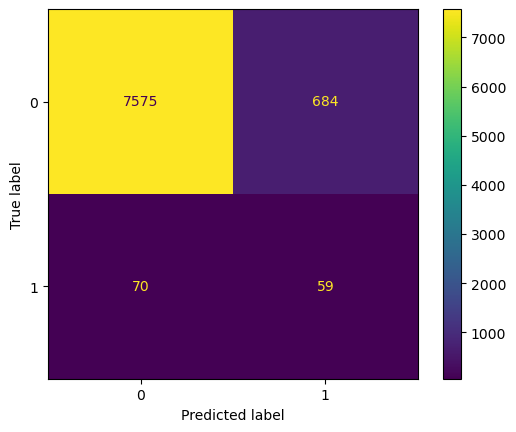

Exception ignored in: <function ResourceTracker.__del__ at 0x10649dbc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x106609bc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x102afdbc0>
Traceback (most recent call last

In [128]:
best_threshold = threshold_finder(lr_best, X_val, y_val)
print(f"\nBeste threshold voor F1: {best_threshold:.3f}")

y_val_proba = lr_best.predict_proba(X_val)[:, 1]
y_val_pred  = (y_val_proba >= best_threshold).astype(int)

print(f"F1-score op validatieset (met beste threshold): "
      f"{f1_score(y_val, y_val_pred):.4f}")

ConfusionMatrixDisplay.from_predictions(y_val, y_val_pred)
print(classification_report(y_val, y_val_pred))